# A first attempt at automating symmetric constraints for SINDy

## Setup

In [1]:
import numpy as np
import pysindy as ps
import scipy
import sympy as sp

Load data:

In [2]:
# read data
data = np.load("../sindy_data/sindy_data_short.npz")

for x in data:
    print(x, data[x].shape)

x (121,)
y (101,)
t (2000,)
spatial_grid (121, 101, 2)
u (121, 101, 2000, 2)
feature_names (2,)
t_coarse (52,)
x_coarse (122,)
y_coarse (101,)
u_coarse (122, 101, 52)
v_coarse (122, 101, 52)
p_coarse (122, 101, 52)
charge_coarse (122, 101, 52)
phi_coarse (122, 101, 52)
Ex_coarse (122, 101, 52)
Ey_coarse (122, 101, 52)


$G$ is the set of transformation matrices s.t. the system follows the same dynamics under the transformation. That is, $\frac{d}{dt}(X g_k^T) = \frac{dX}{dt} g_k^T$ for transformation $g_k \in G$ ($X$'s entries are given as rows)

In [3]:
G = np.array([
    [[1, 0, 0], [0, -1, 0], [0, 0, 1]],  # [a1, a2, a3] -> [a1, -a2, a3]
    [[1, 0, 0], [0, 1, 0], [0, 0, -1]],  # [a1, a2, a3] -> [a1, a2, -a3]
    [[1, 0, 0], [0, -1, 0], [0, 0, -1]],  # [a1, a2, a3] -> [a1, -a2, -a3]
    [[-1, 0, 0], [0, 0, 1], [0, 1, 0]],  # [a1, a2, a3] -> [-a1, a3, a2]
    [[-1, 0, 0], [0, 0, -1], [0, -1, 0]]  # [a1, a2, a3] -> [-a1, -a3, -a2]
])

# convert matrices to sympy substitution rules
a1, a2, a3 = sp.symbols('a1 a2 a3')
A_symb = [a1, a2, a3]
G_subs_rules = []
for g in G:
    subs_rule = {a: sum(g[i, j] * A_symb[j] for j in range(3)) for i, a in enumerate(A_symb)}
    G_subs_rules.append(subs_rule)

The system is $\frac{dX}{dt} = \Theta(X) \Xi$, where $X$, $\Theta(X)$, and $\Xi$ are defined as in Guan et al. 2021.

In [ ]:
# # find POD modes
# charge = data["u"][..., 1]          # (n_x, n_y, n_t) charge-density field only
# n_x, n_y, n_t = charge.shape
# snapshots = charge.reshape(n_x * n_y, n_t)   # each column = one time snapshot

# # POD via SVD: snapshots = Phi @ diag(sigma) @ Vt
# Phi, sigma, Vt = np.linalg.svd(snapshots - snapshots.mean(axis=1, keepdims=True), full_matrices=False)
# np.savez("pod_modes.npz", Phi=Phi, sigma=sigma, Vt=Vt)

In [5]:
pod_data = np.load("pod_modes.npz")
Phi = pod_data["Phi"]
sigma = pod_data["sigma"]
Vt = pod_data["Vt"]

In [6]:
r = 3  # PC1-PC3, as in the paper (PC0 is the mean field, dropped before SVD)
modes = Phi[:, :r]                  # spatial POD modes, reshape to (n_x, n_y, r) to plot

In [7]:
X_raw = (sigma[:r, None] * Vt[:r, :]).T  # paper eq. (4.1): columns are the time series a1, a2, a3

# Normalise each POD amplitude to unit RMS. Guan et al.'s reported model (eq. 4.9) and its
# O(1) fixed points imply their a_i are O(1) (variance-normalised), not the raw sigma*v
# amplitudes, which are O(50) here. Normalising also keeps the degree 1/2/3 library columns
# on one scale instead of spanning ~5 orders of magnitude.
#
# g_3, g_4 in G swap modes 2 and 3, so those two must share a scale factor. The resulting
# D = diag(s1, s23, s23) still commutes with every g_k (all signed permutations that only mix
# e2 <-> e3), so every symmetry constraint built below is unchanged. Coefficients can be
# mapped back to raw units after the fit (see the fit cell).
s1 = np.sqrt(np.mean(X_raw[:, 0] ** 2))
s23 = np.sqrt(np.mean(X_raw[:, 1:3] ** 2))   # shared RMS for the swap-paired modes 2, 3
X_scale = np.array([s1, s23, s23])           # length 3; broadcasts over columns everywhere below
X = X_raw / X_scale

# # Augment X with symmetry-transformed copies
# X_augmented = [X]  # start with identity
# for g in G:
#     X_augmented.append(X @ g.T)
# X = np.concatenate(X_augmented, axis=-1)

Theta = ps.PolynomialLibrary(degree=3, include_interaction=True, include_bias=False)
Theta.fit(X)

PolynomialLibrary(degree=3, include_bias=False)

## Enforcing symmetry

If $g_k \in G$ is linear, then we can write $\Theta(X g_k^T) = \Theta(X) M_k$ for some matrix $M_k$. $M_k$ is defined by mapping each term in the original library $\Theta(X)$ to the transformed library $\Theta(X g_k^T)$ manually.

In [8]:
def build_Mk(library, subs_rule, vars_, monomial_index):
    """Convention: Theta(g x) = Theta(x) @ M_k, i.e. theta_j(g x) = sum_i Theta_x[i] * M[i, j].
    So each coefficient found while processing column j (theta_j) goes into M[i, j].
    """
    n = len(library)
    M = sp.zeros(n, n)
    for j, theta_j in enumerate(library):
        transformed = sp.expand(theta_j.subs(subs_rule, simultaneous=True))
        poly = sp.Poly(transformed, *vars_)
        for exps, coeff in poly.terms():
            i = monomial_index[exps]
            M[i, j] += coeff

    return M

full_library = Theta.get_feature_names(["a1", "a2", "a3"])
full_library = [sp.sympify(" * ".join(f.split(" "))) for f in full_library]
def exponent_tuple(monom, vars_):
    poly = sp.Poly(monom, *vars_)
    if poly.is_zero:
        return tuple([0] * len(vars_))
    return poly.monoms()[0]

# get indices corresponding to each term in the library
monomial_index = {}
for idx, m in enumerate(full_library):
    monomial_index[exponent_tuple(m, A_symb)] = idx

In [9]:
M_list = []

for subs_rule in G_subs_rules:
    M_k = build_Mk(full_library, subs_rule, A_symb, monomial_index)
    M_list.append(M_k)

Substituting into the original system, we get $\Theta(X g_k^T) \Xi = \Theta(X) M_k \Xi = \Theta(X) \Xi g_k^T$. This implies that $M_k \Xi = \Xi g_k^T$, which is a linear constraint on $\Xi$.

More specifically, in the $C\xi = d$ format this can be written as $(I \otimes M_k - g_k \otimes I) \text{vec}(\Xi) = 0$, where $\text{vec}(\Xi)$ is the vectorization of $\Xi$ (stacking columns).

In [10]:
C_list = []
for i in range(len(G)):
    M_numeric = np.array(M_list[i], dtype=float)
    C_list.append(np.kron(np.eye(G[i].shape[0]), M_numeric) - np.kron(G[i], np.eye(M_numeric.shape[0])))

Add the energy-preserving quadratic constraint (Loiseau & Brunton / Schlegel–Noack)

This ties a pure-quadratic term in one equation to a quadratic term in another ($a_2^2$ in $a_1'$  <->  $a_1a_2$ in $a_2'$  <->  $a_1a_3$ in $a_3'$). Condition: sum_i a_i * (quadratic part of a_i') vanishes identically, i.e. for every cubic monomial the symmetrized quadratic-coupling coefficients sum to zero.

In [11]:
from itertools import combinations_with_replacement

n_lib = len(full_library)
n_tgt = len(A_symb)

row = np.zeros(n_tgt * n_lib)
row[0 * n_lib + monomial_index[exponent_tuple(a2**2, A_symb)]] = 1.0
row[1 * n_lib + monomial_index[exponent_tuple(a1*a2, A_symb)]] = 1.0
energy_lhs = row[None, :]

## Solving system with SINDy

In [12]:
constraints_lhs = np.vstack(C_list + [energy_lhs])
constraints_rhs = np.zeros(constraints_lhs.shape[0])

In [13]:
# remove redundant constraints by selecting independent rows of the augmented system
# use QR with column pivoting on A.T to find independent rows of A (constraints_lhs)
A = constraints_lhs
b = constraints_rhs
rank = np.linalg.matrix_rank(A)
if rank == 0:
    # no independent constraints
    constraints_lhs = np.empty((0, A.shape[1]))
    constraints_rhs = np.empty((0,))
else:
    # qr on A.T identifies independent rows of A via pivot indices
    Q, R, piv = scipy.linalg.qr(A.T, pivoting=True)
    independent_row_idx = piv[:rank]
    constraints_lhs = A[independent_row_idx, :]
    constraints_rhs = b[independent_row_idx]

# drop any all-zero rows (safety)
mask = ~np.isclose(constraints_lhs, 0).all(axis=1)
constraints_lhs = constraints_lhs[mask]
constraints_rhs = constraints_rhs[mask]

In [14]:
differentiation_method = ps.FiniteDifference(order=2)
# optimizer = ps.ConstrainedSTLSQ(
#     constraint_lhs=constraints_lhs,
#     constraint_rhs=constraints_rhs,
#     constraint_order="target",
# )
optimizer = ps.ConstrainedSR3(  # this needs all constraints to be independent
    constraint_lhs=constraints_lhs,
    constraint_rhs=constraints_rhs,
    constraint_order="target",
    equality_constraints=True,
    reg_weight_lam=0,
)
model = ps.SINDy(
    differentiation_method=differentiation_method,
    feature_library=Theta,
    optimizer=optimizer,
)

In [15]:
model.fit(X, t=data["t"], feature_names=[a.name for a in A_symb])

# Printed in the unit-RMS-normalised coordinates used for the fit, so the a_i are O(1) and
# these coefficients are directly comparable to Guan et al. eq. (4.9). They still won't match
# to the digit: this is a different time window (t in [3200, 4000] vs [0, 1000]) sampled at
# dt = 0.4 vs the paper's 0.005.
model.print()

# Same model in raw sigma*v amplitude units, if needed. The fit is on y = x / s with
# s = X_scale; a library term with exponents e satisfies theta_e(x/s) = theta_e(x) / prod_k s_k**e_k
# and dy_i/dt = (dx_i/dt) / s_i, so  p_ij = c_ij * s_i / prod_k s_k**e_jk.
feat_names = Theta.get_feature_names([a.name for a in A_symb])
Xi_fit = model.coefficients().T                       # (n_lib, n_targets), normalised coords
Xi_raw = np.array(Xi_fit)
for j, m in enumerate(full_library):
    e = np.array(exponent_tuple(m, A_symb), float)
    Xi_raw[j, :] = Xi_fit[j, :] * X_scale / np.prod(X_scale ** e)
print("\nraw sigma*v amplitude units:")
for i, nm in enumerate([a.name for a in A_symb]):
    terms = [f"{Xi_raw[j, i]:+.4g} {feat_names[j]}"
             for j in range(len(feat_names)) if abs(Xi_raw[j, i]) > 1e-8]
    print(f"({nm})' = " + " ".join(terms))

(a1)' =  0.181 a1 +  0.088 a2^2 + -0.088 a3^2 + -0.124 a1^3 +  0.052 a1 a2^2 +  0.052 a1 a3^2
(a2)' = -1.023 a2 + -0.088 a1 a2 +  0.875 a1^2 a2 +  0.057 a2^3 +  0.063 a2 a3^2
(a3)' = -1.023 a3 +  0.088 a1 a3 +  0.875 a1^2 a3 +  0.063 a2^2 a3 +  0.057 a3^3

raw sigma*v amplitude units:
(a1)' = +0.1809 a1 +0.019 a2^2 -0.019 a3^2 -4.14e-05 a1^3 +0.0002042 a1 a2^2 +0.0002042 a1 a3^2
(a2)' = -1.023 a2 -0.00161 a1 a2 +0.0002913 a1^2 a2 +0.0002237 a2^3 +0.000247 a2 a3^2
(a3)' = -1.023 a3 +0.00161 a1 a3 +0.0002913 a1^2 a3 +0.000247 a2^2 a3 +0.0002237 a3^3


/mmfs1/home/songk42/pysindy/pysindy/optimizers/_constrained_sr3.py:318: UserWarning: Target format constraints are deprecated.
  self.constraint_lhs = reorder_constraints(self.constraint_lhs, n_features)
/mmfs1/home/songk42/pysindy/pysindy/optimizers/_constrained_sr3.py:398: UserWarning: Target format constraints are deprecated.
  self.constraint_lhs = reorder_constraints(


## Verifying the symmetry constraints

Directly check $M_k \Xi = \Xi g_k^T$ for each $g_k \in G$ using the fitted $\Xi$. This is independent of pysindy's internal `constraint_order` convention — it re-derives the physical statement from scratch, so it also catches ordering/wiring bugs in how the constraints were passed to the optimizer.

In [16]:
Xi = model.coefficients().T  # (n_library, n_targets); model.coefficients() returns Xi^T

scale = np.max(np.abs(Xi)) or 1.0
print(f"max|Xi| = {scale:.3e}\n")
print(f"{'g_k':>4} | {'max|M_k Xi - Xi g_k^T|':>24} | {'relative to max|Xi|':>20}")
for k, (Mk, gk) in enumerate(zip(M_list, G)):
    Mk_num = np.array(Mk, dtype=float)
    resid = Mk_num @ Xi - Xi @ gk.T
    max_resid = np.max(np.abs(resid))
    print(f"{k:>4} | {max_resid:24.3e} | {max_resid / scale:20.3e}")

# sanity check: confirm this matches the constraints as actually passed to ConstrainedSR3
# (catches a mismatched `constraint_order` even if the check above somehow passed)
vec_Xi = Xi.flatten(order="F")  # stacking columns, per the derivation above
lhs_resid = np.max(np.abs(constraints_lhs @ vec_Xi - constraints_rhs))
print(f"\nmax|constraints_lhs @ vec(Xi) - constraints_rhs| = {lhs_resid:.3e}")

max|Xi| = 1.023e+00

 g_k |   max|M_k Xi - Xi g_k^T| |  relative to max|Xi|
   0 |                3.941e-15 |            3.852e-15
   1 |                3.941e-15 |            3.852e-15
   2 |                3.608e-15 |            3.526e-15
   3 |                3.553e-15 |            3.472e-15
   4 |                3.553e-15 |            3.472e-15

max|constraints_lhs @ vec(Xi) - constraints_rhs| = 3.941e-15


## Reproducing the paper's figures

I did get the symmetries working (at least for this particular set of symmetires), but this is why I am not convinced that I am using the data correctly...

Figure 2(c,d): spatial POD modes and their amplitude time series.

In [17]:
charge = data["u"][..., 1]          # (n_x, n_y, n_t) charge-density field only
n_x, n_y, n_t = charge.shape
snapshots = charge.reshape(n_x * n_y, n_t)

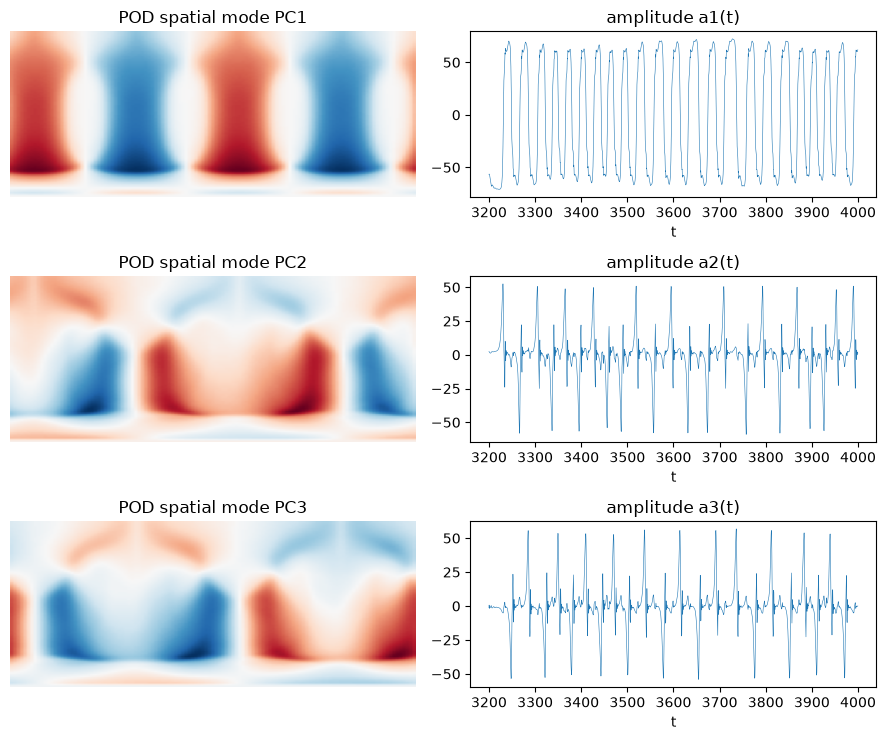

In [18]:
import matplotlib.pyplot as plt

Xp = X * X_scale  # undo the rescaling for physically-meaningful amplitude plots

fig, axes = plt.subplots(r, 2, figsize=(9, 2.5 * r))
for i in range(r):
    spatial = modes[:, i].reshape(n_x, n_y)
    im = axes[i, 0].imshow(spatial.T, origin="lower", aspect="auto", cmap="RdBu_r")
    axes[i, 0].set_title(f"POD spatial mode PC{i + 1}")
    axes[i, 0].axis("off")

    axes[i, 1].plot(data["t"], Xp[:, i], lw=0.4)
    axes[i, 1].set_title(f"amplitude a{i + 1}(t)")
    axes[i, 1].set_xlabel("t")

fig.tight_layout()

Figure 3(a,b): 3D phase portrait of $(a_1, a_2, a_3)$ and its 2D projections

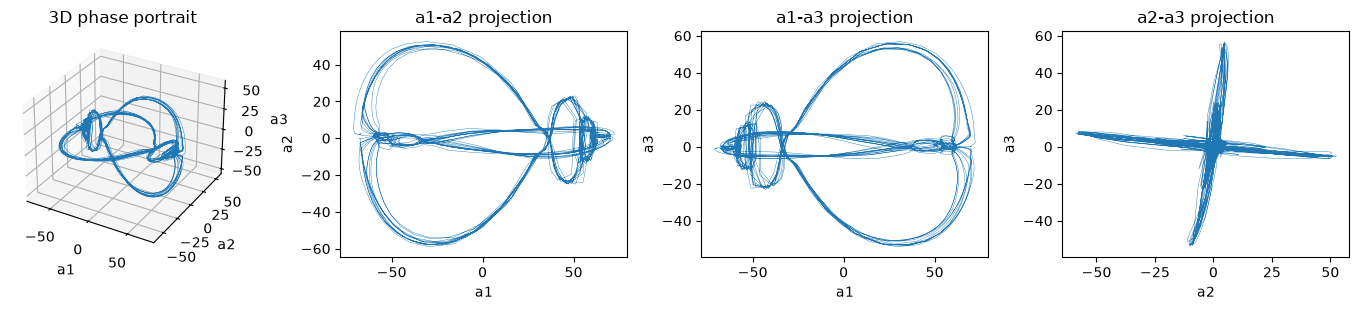

In [19]:
fig = plt.figure(figsize=(14, 3.2))

ax3d = fig.add_subplot(1, 4, 1, projection="3d")
ax3d.plot(Xp[:, 0], Xp[:, 1], Xp[:, 2], lw=0.3)
ax3d.set_xlabel("a1")
ax3d.set_ylabel("a2")
ax3d.set_zlabel("a3")
ax3d.set_title("3D phase portrait")

labels = ["a1", "a2", "a3"]
for i, (p, q) in enumerate([(0, 1), (0, 2), (1, 2)]):
    ax = fig.add_subplot(1, 4, i + 2)
    ax.plot(Xp[:, p], Xp[:, q], lw=0.3)
    ax.set_xlabel(labels[p])
    ax.set_ylabel(labels[q])
    ax.set_title(f"{labels[p]}-{labels[q]} projection")

fig.tight_layout()

Figure 4(a): simulate the fitted SINDy model from the data's initial condition and compare its trajectory to the actual data — the real test of whether the model reproduces the system's behavior, not just the symmetry constraints.

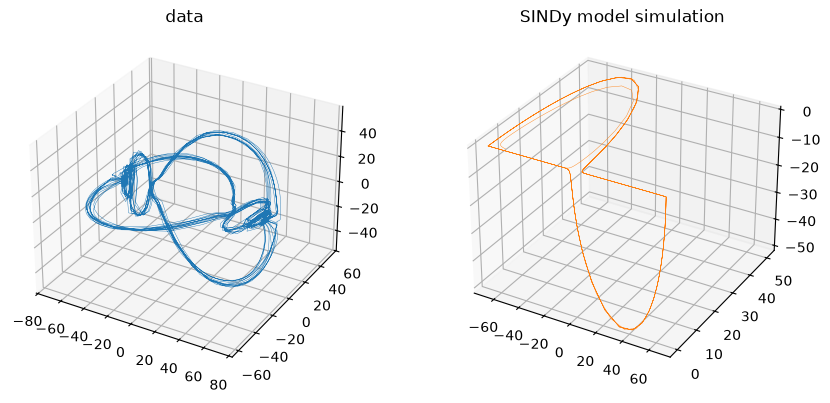

In [23]:
n_sim = 5000  # full 10000-step horizon also runs, but the model damps out well before then
t_sim = data["t"][:n_sim]
X_sim = model.simulate(X[0], t_sim) * X_scale

fig = plt.figure(figsize=(9, 4))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot(Xp[:n_sim, 0], Xp[:n_sim, 1], Xp[:n_sim, 2], lw=0.3)
ax1.set_title("data")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(X_sim[:, 0], X_sim[:, 1], X_sim[:, 2], lw=0.3, color="C1")
ax2.set_title("SINDy model simulation")

fig.tight_layout()